# Dataset over de tijd: opschonen en samenvoegen

Voegt de twee bronnen samen tot één tabel waarin elke rij een auto **op een bepaald moment** is:

| Bron | Periode | Inhoud |
|---|---|---|
| `wayback_cars.csv` | mrt 2023 – dec 2025 | pagina 1 van de zoekresultaten per model per maand |
| `cars.csv` | okt 2026 | het volledige aanbod |

Uitvoer: `dataset_tijd.parquet`. De bronbestanden worden niet aangepast.

Keuzes:
- **Alleen NL** en van Wayback alleen `page_sort == "standard"` (vóór 2023 vooral Duitse auto's en een andere sortering).
- **Bouwjaar 2005 of later**, zoals in `cars.csv`.
- **Leeftijd in jaren met decimalen**: alleen het bouwjaar is bekend, dus we nemen aan dat elke auto midden in
  het jaar is geregistreerd. Met hele jaren wordt elke auto op 1 januari in één keer een jaar ouder,
  wat een nep-sprong in de prijzen geeft.
- **Geen kolom `bron`**: de bron volgt uit de datum (okt 2026 = `cars.csv`, eerder = Wayback).
- **Nieuwprijs voor Wayback**: de mediaan van de exacte nieuwprijzen in `cars.csv` voor hetzelfde merk + model + bouwjaar.
- **Duplicaten blijven staan.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SCRAPE_DATUM_2026 = "2026-10-05"   # einde van de cars.csv-scrape (zelfde als marktindex.ipynb)
WAYBACK_VANAF = "2023-03-01"       # daarvoor vrijwel geen NL-auto's
MIN_BOUWJAAR = 2005
MAX_KM = 600_000                   # daarboven vooral placeholders (bijv. 999.999)
MAX_PRIJS_T_O_V_NIEUW = 1.5        # prijs > 1,5 × nieuwprijs: placeholder of verzamelobject
MAX_AFWIJKING_NIEUWPRIJS = 3       # nieuwprijs > 3× of < 1/3 van de mediaan (zelfde model + bouwjaar): tikfout

EXACTE_BRONNEN = ["autoscout", "rdw_kenteken"]

## 1. Inladen

In [2]:
scrape = pd.read_csv("../webscrape/data/cars.csv")
wayback = pd.read_csv("../webscrape/data/wayback_cars.csv")
cpi = pd.read_csv("cpi.csv", index_col="year")

print("cars.csv:        ", scrape.shape)
print("wayback_cars.csv:", wayback.shape)

cars.csv:         (148662, 10)
wayback_cars.csv: (140650, 13)


## 2. Wayback filteren

Telt per stap hoeveel rijen er afvallen, zodat je dat in je verslag kunt noemen.

In [3]:
wb = wayback.copy()
wb["snapshot_date"] = pd.to_datetime(wb["snapshot_date"])

stappen = [("start", len(wb))]
wb = wb[wb["country"] == "NL"];                      stappen.append(("land = NL", len(wb)))
wb = wb[wb["page_sort"] == "standard"];              stappen.append(("sortering = standard", len(wb)))
wb = wb[wb["snapshot_date"] >= WAYBACK_VANAF];       stappen.append((f"vanaf {WAYBACK_VANAF}", len(wb)))

pd.DataFrame(stappen, columns=["stap", "rijen over"])

,stap,rijen over
0,start,140650
1,land = NL,130430
2,sortering = standard,130430
3,vanaf 2023-03-01,130430


## 3. Nieuwprijs voor Wayback

Wayback heeft vrijwel nooit een nieuwprijs. We nemen de mediaan van de **exacte** nieuwprijzen
(`autoscout` of `rdw_kenteken`) in `cars.csv`:
1. hetzelfde merk + model + bouwjaar → `schatting_cars_model_jaar`;
2. anders hetzelfde merk + model (alle bouwjaren) → `schatting_cars_model`.

In [4]:
exact = scrape[scrape["new_price_source"].isin(EXACTE_BRONNEN)]
per_model_jaar = exact.groupby(["brand", "model", "year"])["new_price_eur"].median()
per_model = exact.groupby(["brand", "model"])["new_price_eur"].median()

wb["year"] = wb["year"].astype("Int64")
sleutel_mj = pd.MultiIndex.from_frame(wb[["brand", "model", "year"]])
sleutel_m = pd.MultiIndex.from_frame(wb[["brand", "model"]])

prijs_mj = pd.Series(per_model_jaar.reindex(sleutel_mj).values, index=wb.index)
prijs_m = pd.Series(per_model.reindex(sleutel_m).values, index=wb.index)

bron = pd.Series(pd.NA, index=wb.index, dtype="object")
bron[prijs_m.notna()] = "schatting_cars_model"
bron[prijs_mj.notna()] = "schatting_cars_model_jaar"
bron[wb["new_price_eur"].notna()] = "autoscout"   # de enkele keer dat Wayback zelf een nieuwprijs heeft
wb["new_price_source"] = bron
wb["new_price_eur"] = wb["new_price_eur"].fillna(prijs_mj).fillna(prijs_m)

wb["new_price_source"].value_counts(dropna=False)

new_price_source
schatting_cars_model_jaar    112400
schatting_cars_model          15930
<NA>                           2100
Name: count, dtype: int64

## 4. Samenvoegen

In [5]:
scrape_t = scrape.assign(bron="scrape_2026", snapshot_date=pd.Timestamp(SCRAPE_DATUM_2026))
wb_t = wb.assign(bron="wayback")

KOLOMMEN = ["bron", "snapshot_date", "brand", "model", "year", "mileage_km", "fuel_type", "transmission",
            "body_type", "price_eur", "new_price_eur", "new_price_source"]
d = pd.concat([wb_t[KOLOMMEN], scrape_t[KOLOMMEN]], ignore_index=True)

d["maand"] = d["snapshot_date"].dt.to_period("M").astype(str)
d["brand_model"] = d["brand"] + " " + d["model"]
d.groupby("bron").size()

bron
scrape_2026    148662
wayback        130430
dtype: int64

## 5. Opschonen (beide bronnen)

Alleen regels, geen indexnummers, zodat het ook na een nieuwe scrape klopt.

In [6]:
stappen = [("start", len(d))]

d = d.dropna(subset=["model", "year", "mileage_km", "price_eur"])
stappen.append(("geen ontbrekend model/bouwjaar/km/prijs", len(d)))

d = d[d["model"] != "Overig"]
stappen.append(('model niet "Overig" (onbekend model)', len(d)))

d = d.dropna(subset=["new_price_eur"])
stappen.append(("nieuwprijs bekend", len(d)))

d = d[d["year"] >= MIN_BOUWJAAR]
stappen.append((f"bouwjaar >= {MIN_BOUWJAAR}", len(d)))

d = d[d["year"] <= d["snapshot_date"].dt.year]
stappen.append(("bouwjaar niet na waarnemingsjaar", len(d)))

d = d[d["mileage_km"] < MAX_KM]
stappen.append((f"km < {MAX_KM:,}", len(d)))

d = d[d["price_eur"] <= MAX_PRIJS_T_O_V_NIEUW * d["new_price_eur"]]
stappen.append((f"prijs <= {MAX_PRIJS_T_O_V_NIEUW} × nieuwprijs", len(d)))

# Tikfouten in de nieuwprijs, bijv. een Ford Focus van €187.673 of een Opel Vivaro van €4,2 miljoen
mediaan_nieuw = d.groupby(["brand_model", "year"])["new_price_eur"].transform("median")
afwijking = d["new_price_eur"] / mediaan_nieuw
d = d[(afwijking <= MAX_AFWIJKING_NIEUWPRIJS) & (afwijking >= 1 / MAX_AFWIJKING_NIEUWPRIJS)]
stappen.append((f"nieuwprijs binnen {MAX_AFWIJKING_NIEUWPRIJS}× de mediaan van model + bouwjaar", len(d)))

d = d.reset_index(drop=True)
d["year"] = d["year"].astype(int)
d["mileage_km"] = d["mileage_km"].astype(int)

pd.DataFrame(stappen, columns=["stap", "rijen over"])

,stap,rijen over
0,start,279092
1,geen ontbrekend model/bouwjaar/km/prijs,278525
2,"model niet ""Overig"" (onbekend model)",277701
3,nieuwprijs bekend,275546
4,bouwjaar >= 2005,267711
5,bouwjaar niet na waarnemingsjaar,267663
6,"km < 600,000",267575
7,prijs <= 1.5 × nieuwprijs,267035
8,nieuwprijs binnen 3× de mediaan van model + bo...,266884


## 6. Afgeleide kolommen

- `age`: leeftijd in jaren met decimalen op het moment van de waarneming
  (`waarnemingsmoment − (bouwjaar + 0,5)`).
- Alle bedragen in **euro's van 2026** met de algemene CPI (CBS), zodat ze vergelijkbaar zijn:
  - `new_price_2026`: nieuwprijs, omgerekend vanaf het **bouwjaar** (een catalogusprijs uit 2010 is in euro's van 2010);
  - `price_2026`: vraagprijs, omgerekend vanaf het **waarnemingsjaar** (een vraagprijs uit 2024 is in euro's van 2024).

  Het model leert zo alleen de echte marktbeweging; toekomstige inflatie komt er later als scenario bij.
  Voor 2026 gebruikt `cpi.csv` het cijfer van september 2026 (het jaarcijfer is nog niet bekend).

In [7]:
moment = d["snapshot_date"].dt.year + (d["snapshot_date"].dt.month - 0.5) / 12
d["age"] = (moment - (d["year"] + 0.5)).clip(lower=0).round(3)

cpi_2026 = cpi.loc[2026, "cpi_all"]
d["new_price_2026"] = (d["new_price_eur"] * cpi_2026 / d["year"].map(cpi["cpi_all"])).round()
d["price_2026"] = (d["price_eur"] * cpi_2026 / d["snapshot_date"].dt.year.map(cpi["cpi_all"])).round()

d[["snapshot_date", "brand_model", "year", "age", "mileage_km", "price_eur", "price_2026",
   "new_price_eur", "new_price_2026"]].sample(5, random_state=1)

,snapshot_date,brand_model,year,age,mileage_km,price_eur,price_2026,new_price_eur,new_price_2026
82949,2023-09-25,Mercedes-Benz GLE 450,2019,4.208,93484,70945,79019.0,123103.0,162853.0
93064,2025-01-04,Porsche 718,2022,2.542,75120,99950,104378.0,203467.0,235331.0
212593,2026-10-05,Volvo XC60,2026,0.292,3962,65950,65950.0,80401.0,80401.0
96174,2023-09-01,Mercedes-Benz B 160,2010,13.208,87553,9995,11132.0,28695.5,44004.0
240831,2026-10-05,Opel Astra,2011,15.292,94354,6950,6950.0,23185.0,34738.0


## 7. Controles

In [8]:
print("Rijen per bron (alleen ter controle, `bron` gaat niet mee in de dataset):")
print(d["bron"].value_counts().to_string(), "\n")

print("Ontbrekend (aandeel):")
print(d.isna().mean().round(3)[lambda s: s > 0].to_string(), "\n")

print("Nieuwprijs-bron:")
print(d["new_price_source"].value_counts(dropna=False).to_string())

Rijen per bron (alleen ter controle, `bron` gaat niet mee in de dataset):
bron
scrape_2026    147006
wayback        119878 

Ontbrekend (aandeel):
body_type    0.446 

Nieuwprijs-bron:
new_price_source
schatting_cars_model_jaar    111929
autoscout                     73856
rdw_kenteken                  38582
schatting                     34568
schatting_cars_model           7949


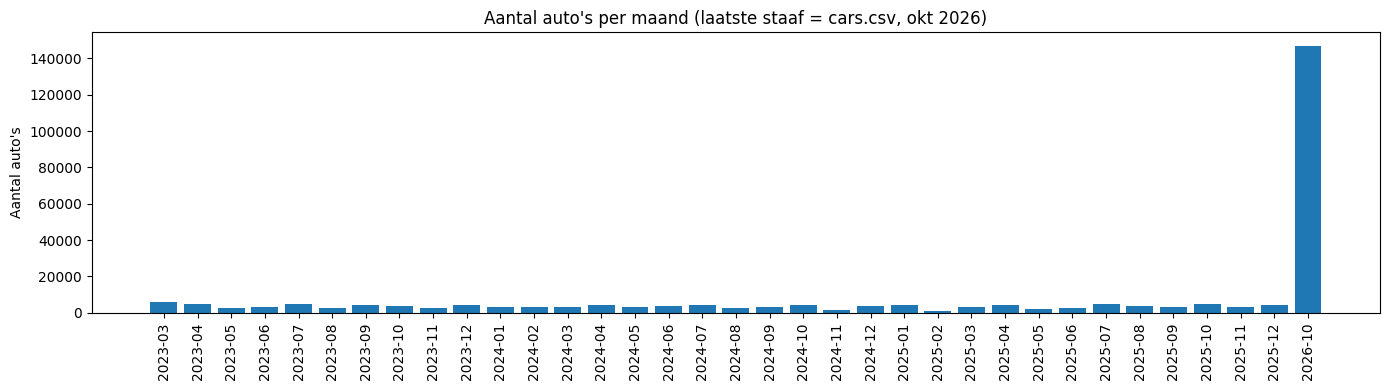

In [9]:
per_maand = d.groupby("maand").size()

plt.figure(figsize=(14, 4))
plt.bar(per_maand.index, per_maand.values)
plt.xticks(rotation=90)
plt.ylabel("Aantal auto's")
plt.title("Aantal auto's per maand (laatste staaf = cars.csv, okt 2026)")
plt.tight_layout()
plt.show()

Vergelijking van de bronnen. Wayback (pagina 1) bevat gemiddeld oudere auto's met meer kilometers dan het
volledige aanbod van 2026. Bij dezelfde auto's (zelfde model, leeftijd, brandstof en km) zijn de prijzen wel
vergelijkbaar: het verschil zit in *welke* auto's erin zitten, en dat vangt het model op met leeftijd, km en model.

In [10]:
d.assign(jaar=d["snapshot_date"].dt.year).groupby("jaar").agg(
    auto_s=("price_eur", "size"),
    mediaan_prijs=("price_eur", "median"),
    mediaan_leeftijd=("age", "median"),
    mediaan_km=("mileage_km", "median"),
).round(2)

,auto_s,mediaan_prijs,mediaan_leeftijd,mediaan_km
jaar,,,,
2023,38039,25731.0,6.04,90925.0
2024,40275,22400.0,6.79,101792.0
2025,41564,22950.0,7.29,105979.5
2026,147006,22940.0,5.29,86631.5


## 8. Opslaan

In [11]:
VOLGORDE = ["snapshot_date", "maand", "brand", "brand_model", "year", "age", "mileage_km",
            "fuel_type", "transmission", "body_type", "price_eur", "price_2026",
            "new_price_eur", "new_price_2026", "new_price_source"]
d[VOLGORDE].to_parquet("dataset_tijd.parquet", index=False)
print(f"{len(d)} rijen opgeslagen in dataset_tijd.parquet")

266884 rijen opgeslagen in dataset_tijd.parquet


## Kolommen in `dataset_tijd.parquet`

| Kolom | Betekenis |
|---|---|
| `snapshot_date`, `maand` | moment van de waarneming (okt 2026 = `cars.csv`, eerder = Wayback); split hierop voor de backtest |
| `brand`, `brand_model` | merk, en merk + model samen (modelnamen zoals `320` bestaan bij meerdere merken) |
| `year`, `age` | bouwjaar en leeftijd (jaren, met decimalen) op het moment van de waarneming |
| `mileage_km`, `fuel_type`, `transmission` | kenmerken |
| `body_type` | **alleen gevuld voor `cars.csv` (okt 2026)**, NaN voor Wayback: niet als feature gebruiken |
| `price_eur` | vraagprijs zoals op de site (euro's van het waarnemingsjaar) |
| `price_2026` | vraagprijs in euro's van 2026: **het doel voor het model** |
| `new_price_eur` | nieuwprijs in euro's van het bouwjaar; `new_price_source` zegt hoe hij gevonden is |
| `new_price_2026` | nieuwprijs in euro's van 2026: gebruik deze als feature |

**Beperkingen:** leeftijd is benaderd (geen registratiemaand), Wayback is pagina 1 en niet het hele aanbod,
en er is geen data van januari tot september 2026.